In [65]:
import pandas as pd
import numpy as np

train = pd.read_csv("train.csv")

y = np.log1p(train["hours_spent"])
X = train.drop(columns=["hours_spent", "log_hours", "hours_bucket", "project_id"])

In [66]:
def add_features(df):
    df = df.copy()

    df["biggest_commit_share"] = df["max_lines_in_one_commit"] / df["lines_added_total"].replace(0, np.nan)
    df["lines_per_active_day"] = df["lines_of_code"] / df["active_commit_days"].replace(0, np.nan)
    df["commits_per_active_day"] = df["num_commits"] / df["active_commit_days"].replace(0, np.nan)
    df["active_day_ratio"] = df["active_commit_days"] / (df["project_span_days"] + 1)

    return df

In [67]:
ORDER_MAPS = {
    "author_prior_projects": {"0": 0, "1-2": 1, "3-5": 2, "6+": 3},
    "author_account_age_years": {"<1": 0, "1-2": 1, "3-5": 2, "6+": 3},
}

def encode_ordered(df):
    df = df.copy()
    for col, mapping in ORDER_MAPS.items():
        df[col] = df[col].astype(str).map(mapping)
    return df

In [68]:
print(train["author_account_age_years"].unique())

<StringArray>
['1-2', '3-5', '<1', '6+']
Length: 4, dtype: str


In [69]:
def encode_categories(df):
    df = df.copy()
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].astype("category")
    return df

In [70]:
def prepare(df):
    df = add_features(df)
    df = encode_ordered(df)
    df = encode_categories(df)
    return df

X = prepare(X)

print(X.shape)
print(X.dtypes.value_counts())
X.head()

(4500, 73)
int64       32
float64     19
bool        12
category     5
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64


C:\Users\Fujitsu\AppData\Local\Temp\ipykernel_15956\3138021966.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,num_commits,active_commit_days,project_span_days,commit_cadence,pct_commits_weekend,pct_commits_late_night,lines_added_total,lines_deleted_total,churn_ratio,median_lines_per_commit,...,num_issues,num_pull_requests,num_releases,is_forked_from_template,author_prior_projects,author_account_age_years,biggest_commit_share,lines_per_active_day,commits_per_active_day,active_day_ratio
0,44,15,56,daily,0.2045,0.4545,8500,2900,0.3438,128.5,...,0,0,0,False,0,1,0.188235,306.666667,2.933333,0.263158
1,9,3,76,sporadic,0.8889,0.0000,500,100,0.2484,32.0,...,0,0,0,False,0,2,0.800000,100.000000,3.000000,0.038961
2,12,1,0,frequent,1.0000,0.0000,5900,100,0.0247,64.5,...,0,0,0,False,0,2,0.525424,1300.000000,12.000000,1.000000
3,4,1,0,frequent,0.0000,0.2500,6000,0,0.0000,1904.0,...,0,0,0,False,0,0,0.366667,300.000000,4.000000,1.000000
4,7,3,64,sporadic,0.8571,0.0000,800,0,0.0419,198.0,...,0,0,0,False,0,1,0.250000,200.000000,2.333333,0.046154


In [71]:
import lightgbm as lgb
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [72]:
oof = np.zeros(len(X))
models = []

In [73]:
for fold,(train_idx, test_idx) in enumerate(kf.split(X)):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    model = lgb.LGBMRegressor(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=20,
        subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8,
        random_state=42,
        verbose=-1,
    )

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_te,y_te)],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )

    oof[test_idx] = model.predict(X_te)
    models.append(model)
    print(f"Fold {fold}: used {model.best_iteration_} trees")

d:\Xin Bing\VSC\hour-detective\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 0: used 198 trees


d:\Xin Bing\VSC\hour-detective\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: used 196 trees


d:\Xin Bing\VSC\hour-detective\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: used 386 trees


d:\Xin Bing\VSC\hour-detective\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 3: used 293 trees


d:\Xin Bing\VSC\hour-detective\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4: used 421 trees


In [74]:
from sklearn.metrics import root_mean_squared_log_error

true_hours = train["hours_spent"]
pred_hours = np.expm1(oof).clip(0, 140.7)

score = root_mean_squared_log_error(true_hours, pred_hours)

baseline_guess = np.full(len(y), np.expm1(y.mean()))
baseline = root_mean_squared_log_error(true_hours, baseline_guess)

print(f"Baseline (same guess for all): {baseline:.4f}")
print(f"LightGBM: {score:.4f}")

Baseline (same guess for all): 0.9623
LightGBM: 0.6584


In [75]:
importance = pd.Series(0.0, index=X.columns)
for m in models:
    importance += m.booster_.feature_importance(importance_type="gain")

print((importance / len(models)).sort_values(ascending=False).head(15))

active_commit_days         9050.533069
lines_added_total          3610.431226
lines_of_code              2903.906752
description_word_count     2262.865413
num_commits                1813.196645
lines_deleted_total        1481.982664
median_lines_per_commit    1477.976111
num_source_files           1299.264354
primary_language            946.655371
project_span_days           921.487129
pct_generic_commit_msgs     889.988814
biggest_commit_share        856.388643
comment_line_ratio          812.109553
pct_commits_weekend         802.165587
active_day_ratio            785.711891
dtype: float64


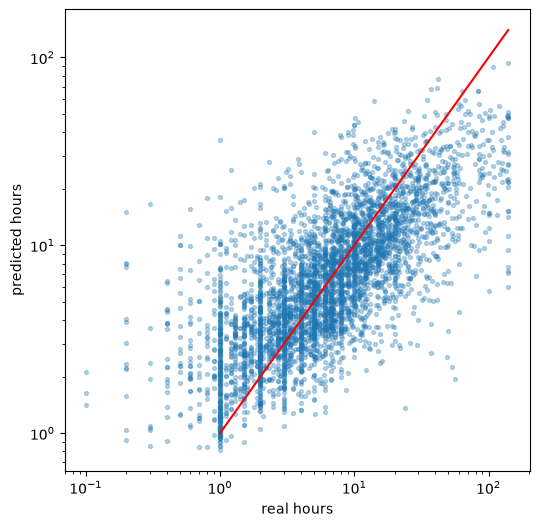

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(true_hours, pred_hours, alpha=0.3, s=8)
plt.plot([1, 140], [1, 140], color="red")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("real hours")
plt.ylabel("predicted hours")
plt.show()

In [77]:
print(train["hours_spent"].describe())
print()
print(y.describe())
print()
print("Projects under 1 hour: ", (train["hours_spent"] < 1).sum())
print("Projects at the cap: ", (train["hours_spent"] >= 140.7).sum())
print()
print(train["hours_bucket"].value_counts())

count    4500.000000
mean       12.136178
std        19.047682
min         0.100000
25%         2.700000
50%         6.000000
75%        12.900000
max       140.700000
Name: hours_spent, dtype: float64

count    4500.000000
mean        2.037927
std         0.962439
min         0.095310
25%         1.308333
50%         1.945910
75%         2.631889
max         4.953712
Name: hours_spent, dtype: float64

Projects under 1 hour:  151
Projects at the cap:  24

hours_bucket
<10       2985
10-30     1120
30-100     332
100+        63
Name: count, dtype: int64
